In [178]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

In [179]:
df = pd.read_csv('E:\pyspider\ml\Machine Learning\Real estate.csv')

<>:1: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:1: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\mokshith.000\AppData\Local\Temp\ipykernel_772\1577326139.py:1: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  df = pd.read_csv('E:\pyspider\ml\Machine Learning\Real estate.csv')


In [180]:
df.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1


In [181]:
df
x=df.drop(columns=['Y house price of unit area'])
y=df['Y house price of unit area']

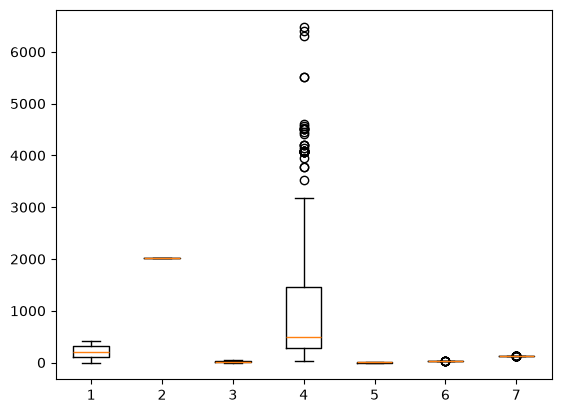

In [182]:
plt.boxplot(x)
plt.show()

In [183]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [184]:
model=LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ -0.01, 5.41, -0.27,..., 1.08,226.05,-30.13]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['No','X1 transaction date','X2 house age',..., 'X4 number of convenience stores','X5 latitude','X6 longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.282e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [185]:
ytrain_pred=model.predict(X_train)
train_score=r2_score(y_train,ytrain_pred)
print(f'Train score {train_score}')

ytest_pred=model.predict(X_test)
test_score=r2_score(y_test,ytest_pred)
print(f'Test score {test_score}')

Train score 0.5604074935510658
Test score 0.674522867035095


In [186]:
Scaling = RobustScaler()
Normalising=MinMaxScaler()

In [187]:
cols_norm = ["X1 transaction date", "X2 house age", "X3 distance to the nearest MRT station", "X5 latitude", "X6 longitude"]
cols_norm = ["X1 transaction date", "X2 house age", "X3 distance to the nearest MRT station", "X5 latitude", "X6 longitude"]
updated_X_train = X_train.copy()
updated_X_test = X_test.copy()
updated_X_train[cols_norm] = Normalising.fit_transform(X_train[cols_norm])

In [188]:
updated_X_train[["X4 number of convenience stores"]] = Scaling.fit_transform(X_train[["X4 number of convenience stores"]])

In [189]:


# make sure scalers are fitted on the training data, then transform the test set
updated_X_test[cols_norm] = Normalising.transform(X_test[cols_norm])
updated_X_test[["X4 number of convenience stores"]] = Scaling.transform(X_test[["X4 number of convenience stores"]])

In [190]:
model_poly = LinearRegression()
model_poly.fit(updated_X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ -0.01, 4.95,-11.73,..., 5.41, 18.65, -2.74]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['No','X1 transaction date','X2 house age',..., 'X4 number of convenience stores','X5 latitude','X6 longitude']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,39.69
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [191]:
ytrain_pred=model_poly.predict(updated_X_train)
train_score=r2_score(y_train,ytrain_pred)
print(f'Train score {train_score}')

ytest_pred=model_poly.predict(updated_X_test)
test_score=r2_score(y_test,ytest_pred)
print(f'Test score {test_score}')

Train score 0.5604074935510714
Test score 0.67452286703508


In [192]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'RandomForestRegressor': RandomForestRegressor(random_state=42, n_estimators=300),
    'GradientBoostingRegressor': GradientBoostingRegressor(random_state=42),
    'SVR': SVR(kernel='rbf')
}

for name, model in models.items():
    model.fit(updated_X_train, y_train)
    preds = model.predict(updated_X_test)
    score = r2_score(y_test, preds)
    print(f'{name}: R² = {score:.4f}')

RandomForestRegressor: R² = 0.8067
GradientBoostingRegressor: R² = 0.7822
SVR: R² = -0.0851
